# Lab assignment №1, part 2

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the second part of the assignment. First and third parts are waiting for you in the same directory.*__

## Part 2. Data preprocessing, model training and evaluation.

### 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [79]:
# If on colab, uncomment the following lines

# ! wget https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv

In [80]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

dataset = pd.read_csv('car_data.csv', delimiter=',', header=None).values
data = dataset[:,1:-1].astype(int)
target = dataset[:, -1]
print(data.shape, target.shape)

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.35, random_state=42)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(846, 18) (846,)
(549, 18) (549,) (297, 18) (297,)


To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [81]:
X_train_pd = pd.DataFrame(X_train)

# First 15 rows of our dataset.
X_train_pd.head(15)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,95,41,82,170,65,9,145,46,19,145,163,314,140,64,4,8,199,207
1,104,57,103,222,72,12,221,30,25,177,223,718,218,72,11,12,186,195
2,91,42,66,169,66,7,145,44,19,140,169,325,159,67,4,0,201,207
3,109,52,95,189,58,4,227,29,25,158,262,776,217,82,0,19,187,186
4,95,47,73,195,70,7,167,38,20,152,184,430,185,69,9,19,200,206
5,81,44,72,139,60,6,153,44,19,146,180,347,178,81,1,15,182,186
6,93,34,66,140,56,7,130,51,18,120,151,251,114,62,5,29,201,207
7,89,43,77,147,54,8,144,46,19,146,163,308,174,64,13,5,194,201
8,117,52,110,228,65,12,212,31,24,163,228,668,220,66,21,25,194,205
9,109,49,109,193,59,10,207,32,24,156,225,635,213,70,13,31,191,202


Methods `describe` and `info` deliver some useful information.

In [82]:
X_train_pd.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
count,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000
mean,93.520947,44.675774,81.801457,168.204007,61.644809,8.457195,167.327869,41.273224,20.468124,147.438980,186.734062,431.540984,173.763206,72.158470,6.522769,12.646630,188.998179,195.854281
std,8.063277,6.154680,15.928751,33.047995,7.110666,3.945857,32.506680,7.777590,2.526030,14.631309,30.436279,171.479332,31.793047,7.335198,4.980796,8.833356,6.298389,7.449629
min,76.000000,33.000000,42.000000,104.000000,47.000000,2.000000,114.000000,26.000000,17.000000,118.000000,131.000000,191.000000,112.000000,59.000000,0.000000,0.000000,176.000000,181.000000
25%,87.000000,40.000000,70.000000,140.000000,57.000000,7.000000,146.000000,34.000000,19.000000,136.000000,167.000000,317.000000,148.000000,67.000000,2.000000,6.000000,184.000000,191.000000
50%,93.000000,44.000000,79.000000,165.000000,61.000000,8.000000,157.000000,43.000000,20.000000,145.000000,177.000000,363.000000,173.000000,71.000000,6.000000,11.000000,189.000000,197.000000
75%,99.000000,49.000000,98.000000,195.000000,66.000000,10.000000,196.000000,46.000000,23.000000,159.000000,216.000000,576.000000,196.000000,75.000000,10.000000,19.000000,193.000000,201.000000
max,117.000000,59.000000,110.000000,306.000000,126.000000,52.000000,265.000000,59.000000,29.000000,186.000000,288.000000,1018.000000,268.000000,127.000000,22.000000,40.000000,206.000000,211.000000


In [83]:
X_train_pd.info()

<class 'pandas.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 18 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       549 non-null    int64
 1   1       549 non-null    int64
 2   2       549 non-null    int64
 3   3       549 non-null    int64
 4   4       549 non-null    int64
 5   5       549 non-null    int64
 6   6       549 non-null    int64
 7   7       549 non-null    int64
 8   8       549 non-null    int64
 9   9       549 non-null    int64
 10  10      549 non-null    int64
 11  11      549 non-null    int64
 12  12      549 non-null    int64
 13  13      549 non-null    int64
 14  14      549 non-null    int64
 15  15      549 non-null    int64
 16  16      549 non-null    int64
 17  17      549 non-null    int64
dtypes: int64(18)
memory usage: 77.3 KB


### 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

#### 2.0. Data preprocessing
* Make some transformations of the dataset (if necessary). Briefly explain the transformations

In [84]:
X_mean = np.mean(X_train, axis=0)
X_std = np.std(X_train, axis=0)

X_train = (X_train - X_mean)/X_std

Для каждого признака вычел среднее и разделил на стандартное отклонение. Это приводит признаки к одному масштабу. Среднее и стандартное отклонение посчитал только по train, затем использовал их для test.

#### 2.1. Basic logistic regression
* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

In [85]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

model = LogisticRegression(solver='saga',tol=1e-3,max_iter=500, random_state=42)

settings = {
    "C": [0.001, 0.1, 1, 10, 100, 1000]
}

search = GridSearchCV(
    estimator=model,
    param_grid=settings,
    cv=5,
    scoring="accuracy"
)

search.fit(X_train, y_train)

print("best param", search.best_params_)
print("mean accyr", search.best_score_)

best param {'C': 1000}
mean accyr 0.7977814845704755


In [86]:
pd.DataFrame(search.cv_results_)[[
    "param_C",
    "mean_test_score",
    "std_test_score"
]]

,param_C,mean_test_score,std_test_score
0,0.001,0.468207,0.052087
1,0.100,0.748691,0.020592
2,1.000,0.792327,0.014864
3,10.000,0.786856,0.011482
4,100.000,0.795963,0.012820
5,1000.000,0.797781,0.015010


In [87]:
from sklearn.metrics import accuracy_score, f1_score

X_test = (X_test - X_mean)/X_std
y_pred = search.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="macro")

print("accuracy", accuracy )
print("f1", f1)


accuracy 0.8282828282828283
f1 0.8213341018591743


In [88]:
y_prob = search.predict_proba(X_test)
# print(y_prob.shape)
# print(y_prob)

In [89]:
# You might use this command to install scikit-plot. 
# Warning, if you a running locally, don't call pip from within jupyter, call it from terminal in the corresponding 
# virtual environment instead

# ! pip install scikit-plot

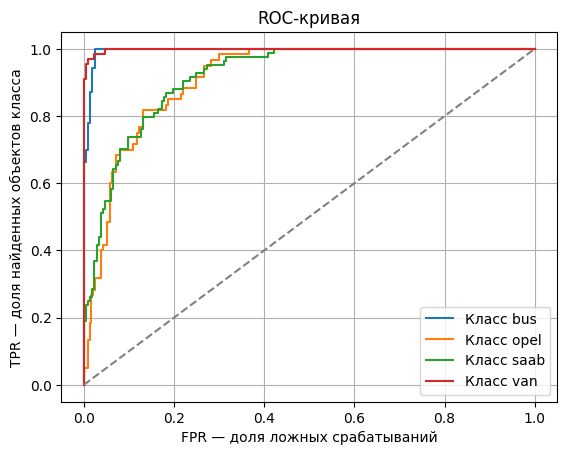

In [90]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

for class_idx in range(len(search.classes_)):   
    mask_class = (y_test ==  search.classes_[class_idx])
    class_prob = y_prob[:, class_idx]
    fpr, tpr, thresholds = roc_curve(mask_class, class_prob)
    plt.plot(fpr, tpr, label=f"Класс {search.classes_[class_idx]}")


plt.plot([0, 1], [0, 1], "--", color="gray")

plt.xlabel("FPR — доля ложных срабатываний")
plt.ylabel("TPR — доля найденных объектов класса")
plt.title("ROC-кривая")
plt.legend()
plt.grid()
plt.show()

#### 2.2. PCA: explained variance plot
* Apply the PCA to the train part of the data. Build the explaided variance plot. 

In [91]:
# print(X_train.mean(axis=0))
# print(X_train.std(axis=0))

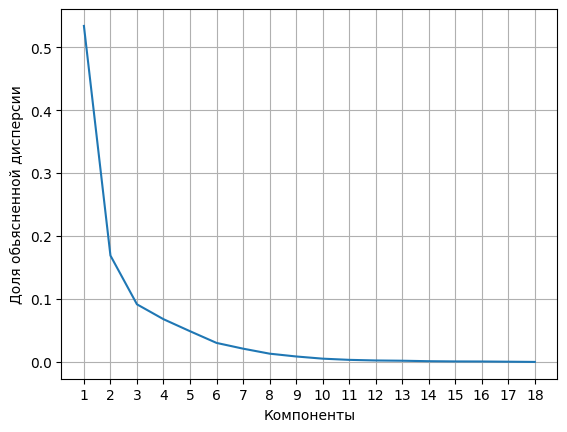

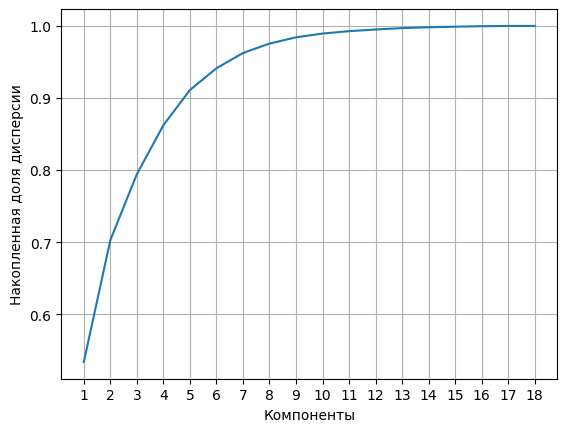

In [92]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X_train)
ratio = pca.explained_variance_ratio_
cum = np.cumsum(ratio)
component = np.arange(1, len(ratio) + 1)
plt.plot(component, ratio)
plt.xlabel("Компоненты")
plt.ylabel("Доля обьясненной дисперсии")
plt.xticks(component)
plt.grid()
plt.show()


plt.plot(component, cum)
plt.xlabel("Компоненты")
plt.ylabel("Накопленная доля дисперсии")
plt.xticks(component)
plt.grid()
plt.show()



In [93]:
pca_selected = PCA(n_components=7)
pca_selected.fit(X_train)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",7
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

#### 2.3. PCA trasformation
* Select the appropriate number of components. Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train` and `test` parts.*

In [94]:
X_train_pca = pca_selected.transform(X_train)
X_test_pca =pca_selected.transform(X_test)
X_test_pca.shape 

(297, 7)

**Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.**

#### 2.4. Logistic regression on PCA-preprocessed data.
* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

In [95]:
model_pca = LogisticRegression(
    solver="saga",
    tol=1e-3,
    max_iter=500,
    random_state=42
)

search_pca = GridSearchCV(
    estimator=model_pca,
    param_grid=settings,
    cv=5,
    scoring="accuracy"
)

search_pca.fit(X_train_pca, y_train)

# print("best_params", search_pca.best_params_)
# print("best_score", search_pca.best_score_)

y_pred_pca = search_pca.predict(X_test_pca)

accuracy_pca = accuracy_score(y_test, y_pred_pca)
f1_pca = f1_score(y_test, y_pred_pca, average="macro")

print("accuracy", accuracy_pca)
print("f1_pca", f1_pca )


accuracy 0.6464646464646465
f1_pca 0.6324481029097443


In [96]:
y_prob_pca = search_pca.predict_proba(X_test_pca)


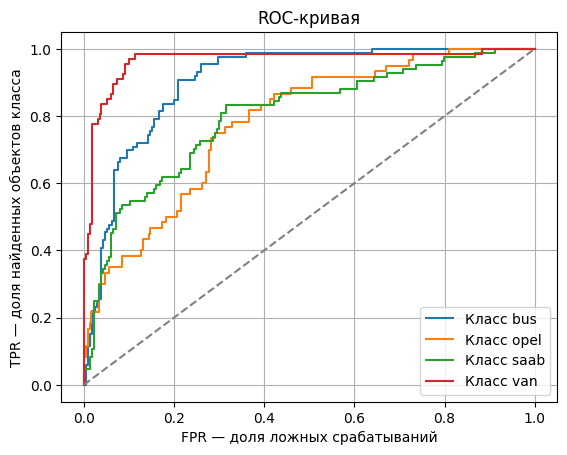

In [97]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

for class_idx in range(len(search_pca.classes_)):   
    mask_class = (y_test ==  search_pca.classes_[class_idx])
    class_prob = y_prob_pca[:, class_idx]
    fpr, tpr, thresholds = roc_curve(mask_class, class_prob)
    plt.plot(fpr, tpr, label=f"Класс {search_pca.classes_[class_idx]}")


plt.plot([0, 1], [0, 1], "--", color="gray")

plt.xlabel("FPR — доля ложных срабатываний")
plt.ylabel("TPR — доля найденных объектов класса")
plt.title("ROC-кривая")
plt.legend()
plt.grid()
plt.show()

In [98]:
print("Без PCA:", accuracy, f1)
print("С PCA:", accuracy_pca, f1_pca)

Без PCA: 0.8282828282828283 0.8213341018591743
С PCA: 0.6464646464646465 0.6324481029097443



Выводы:

Перед PCA данные уже стандартизированы. Здесь это важно, потому что масштабы признаков разные: без стандартизации признаки с большей дисперсией сильнее влияли бы на главные компоненты.

Выбрал 7 компонент, так как  они сохраняют около 96.2% дисперсии. 

После PCA accuracy снизилась с 0.828 до 0.646, а F1 — с 0.821 до 0.632. Таким образом, сокращение размерности с 18 до 7 признаков ухудшило качество классификации.

PCA выбирает направления с наибольшей дисперсией, не учитывая метки классов. Поэтому отброшенные компоненты с небольшой дисперсией могли содержать информацию, полезную для различения классов. Основная цель PCA — уменьшение размерности данных, а не гарантированное повышение точности модели.


#### 2.5. Decision tree
* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

In [99]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)

tree_params = {
    "max_depth":list(range(1,11))
}

search_tree = GridSearchCV(
    estimator=tree,
    param_grid=tree_params,
    cv=5,
    scoring="accuracy"
)

search_tree.fit(X_train, y_train)

y_pred_tree = search_tree.predict(X_test)

accuracy_tree = accuracy_score(y_test, y_pred_tree)
f1_tree = f1_score(y_test, y_pred_tree, average="macro")

print("accuracy", accuracy_tree)
print("f1_tree", f1_tree )
print(search_tree.best_params_)


accuracy 0.7205387205387206
f1_tree 0.7042413176009735
{'max_depth': 8}


#### 2.6. Bagging.
Here starts the ensembling part.

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ (with step 5).

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble? 

In [100]:
N = X_train.shape[0]
trees = []

rng = np.random.default_rng(42)

for i in range(100):
    indx = rng.choice(N, size=N, replace=True)
    X_boot = X_train[indx]
    y_boot = y_train[indx]
    tree = DecisionTreeClassifier(max_depth=search_tree.best_params_["max_depth"], random_state=42 + i)
    tree.fit(X_boot, y_boot)
    trees.append(tree)


tree_accuracy = []
tree_f1_macro = []

for n in range(2,101,5):
    pred_prob = []

    for tree in trees[:n]:
        pred_prob.append(tree.predict_proba(X_test))

    arr = np.array(pred_prob)
    av_prob = np.mean(arr, axis=0)
    class_idx = np.argmax(av_prob, axis=1)
    y_pred_ansambl = trees[0].classes_[class_idx]
    accuracy_ansamble = accuracy_score(y_test, y_pred_ansambl)
    f1_ansamble= f1_score(y_test, y_pred_ansambl, average="macro")
    tree_accuracy.append(accuracy_ansamble)
    tree_f1_macro.append(f1_ansamble)

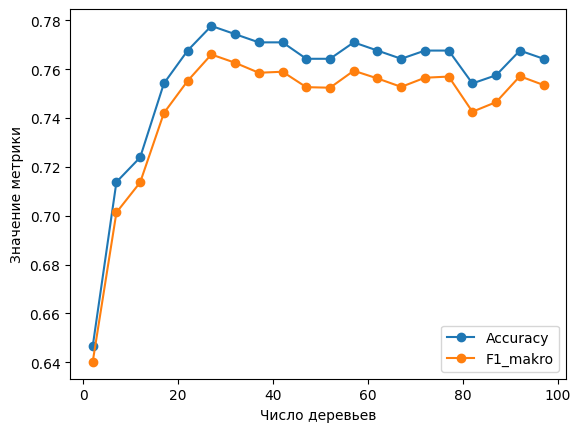

In [101]:
sizes = list(range(2, 101, 5))
plt.plot(sizes, tree_accuracy, marker="o",
    label="Accuracy")
plt.xlabel("Число деревьев")
plt.ylabel("Значение метрики")
plt.plot(sizes, tree_f1_macro, marker="o",
    label="F1_makro")
plt.legend()
plt.show()



Лучшая accuracy около 0.778 получилась при числе деревьев 27. Лучший F1 около 0.766 — при 27. 

Глубина, выбранная для одиночного дерева, не обязательно оптимальна для ансамбля. Бэггинг уменьшает разброс предсказаний, поэтому в нём могут лучше работать более глубокие деревья. Для проверки нужно отдельно подобрать глубину ансамбля на кросс-валидации.

In [102]:
search.best_params_
N = X_train.shape[0]
log_models = []

rng = np.random.default_rng(42)

for i in range(100):
    indx = rng.choice(N, size=N, replace=True)
    X_boot = X_train[indx]
    y_boot = y_train[indx]
    model = LogisticRegression(C=search.best_params_["C"], solver="saga",
                           tol=1e-3, max_iter=2000, random_state=42 + i)
    model.fit(X_boot, y_boot)
    log_models.append(model)


log_accuracy = []
log_f1_macro = []

for n in range(2,101,5):
    pred_prob = []

    for mod in log_models[:n]:
        pred_prob.append(mod.predict_proba(X_test))

    arr = np.array(pred_prob)
    av_prob = np.mean(arr, axis=0)
    class_idx = np.argmax(av_prob, axis=1)
    y_pred_log = log_models[0].classes_[class_idx]
    accuracy_log = accuracy_score(y_test, y_pred_log)
    f1_log= f1_score(y_test, y_pred_log, average="macro")
    log_accuracy.append(accuracy_log)
    log_f1_macro.append(f1_log)

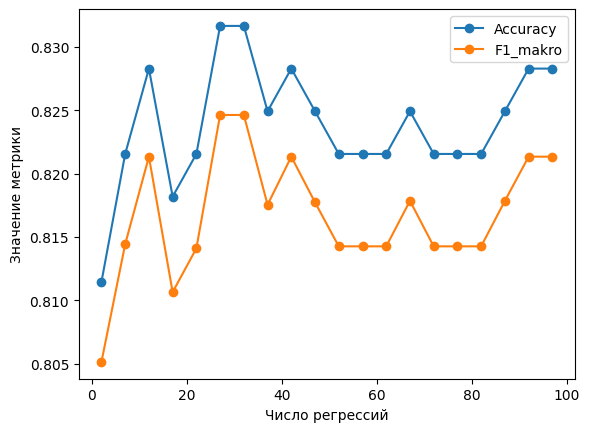

In [103]:
sizes = list(range(2, 101, 5))
plt.plot(sizes, log_accuracy, marker="o",
    label="Accuracy")
plt.xlabel("Число регрессий")
plt.ylabel("Значение метрики")
plt.plot(sizes, log_f1_macro, marker="o",
    label="F1_makro")
plt.legend()
plt.show()



Лучшая accuracy около 0.832 получилась при числе регрессий 27, 32. Лучший F1 около 0.825 — при 27, 32.

#### 2.7. Random Forest
Now we will work with the Random Forest (its `sklearn` implementation).

* * Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

In [104]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=52,
    random_state=42,
    max_depth=search_tree.best_params_["max_depth"],
)

forest.fit(X_train, y_train)

y_pred_forest = forest.predict(X_test)
y_pred_forest.shape
accuracy_forest = accuracy_score(y_test, y_pred_forest)
f1_forest = f1_score(y_test, y_pred_forest, average="macro")
print("accuracy_forest", accuracy_forest)
print("f1_forest", f1_forest)

accuracy_forest 0.7609427609427609
f1_forest 0.7502176560737415


In [105]:
forest_accuracy = []
forest_f1_macro = []

for n in range(2,101,5):
    
    forest = RandomForestClassifier(
        n_estimators=n,
        random_state=42,
        max_depth=search_tree.best_params_["max_depth"],
    )

    forest.fit(X_train, y_train)

    y_pred_forest = forest.predict(X_test)
  
    accuracy_forest = accuracy_score(y_test, y_pred_forest)
    f1_forest= f1_score(y_test, y_pred_forest, average="macro")
    forest_accuracy.append(accuracy_forest)
    forest_f1_macro.append(f1_forest)


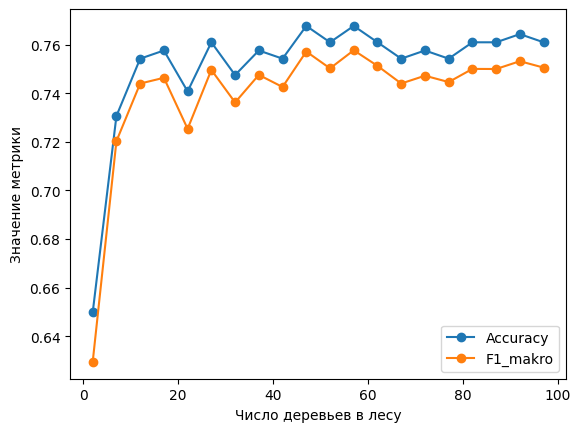

In [106]:
sizes = list(range(2, 101, 5))
plt.plot(sizes, forest_accuracy, marker="o",
    label="Accuracy")
plt.xlabel("Число деревьев в лесу")
plt.ylabel("Значение метрики")
plt.plot(sizes, forest_f1_macro, marker="o",
    label="F1_makro")
plt.legend()
plt.show()



Лучшая accuracy около 0.768 получилась при числе деревьев 47, 57. Лучший F1 около 0.758 — при 57. Выбрал 57. В бэггинге выбрал 27 деревьев и 27 регрессий. 

В бэггинге деревьев при каждом разбиении рассматривались все 18 признаков, а в случайном лесу для каждого разбиения выбиралось случайное подмножество признаков. Из-за этого деревья могут реже ошибаться на одних и тех же объектах, поэтому лучший размер ансамбля может отличаться.

#### 2.8. Learning curve
Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected on 1 part, 2 parts (combined, so the train size in increased by 2 times), 3 parts and so on.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score - dataset size.

* Analyse the final plot. Can you make any conlusions using it? 

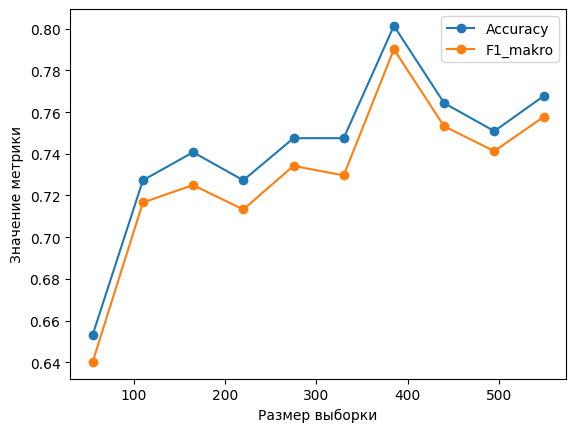

In [107]:
# Select by accuracy, then by F1 when accuracy is tied.
best_forest_index = max(
    range(len(sizes)),
    key=lambda i: (forest_accuracy[i], forest_f1_macro[i])
)
best_forest_n = sizes[best_forest_index]

forest_curve = RandomForestClassifier(
    n_estimators=best_forest_n,
    random_state=42,
    max_depth=search_tree.best_params_["max_depth"],
)

N = X_train.shape[0]
size = list(range(55, N, 55))
size.append(N)
accuracy_forest_lc = []
f1_forest_lc = []

for sz in size:

    X_small = X_train[:sz]
    y_small = y_train[:sz]
    forest_curve.fit(X_small, y_small)

    y_pred_forest_cur = forest_curve.predict(X_test)
    accuracy_forest_lc.append(accuracy_score(y_test, y_pred_forest_cur))
    f1_forest_lc.append(f1_score(y_test, y_pred_forest_cur, average="macro"))


plt.plot(size, accuracy_forest_lc, marker="o",
    label="Accuracy")
plt.xlabel("Размер выборки")
plt.ylabel("Значение метрики")
plt.plot(size, f1_forest_lc, marker="o",
    label="F1_makro")
plt.legend()
plt.show()






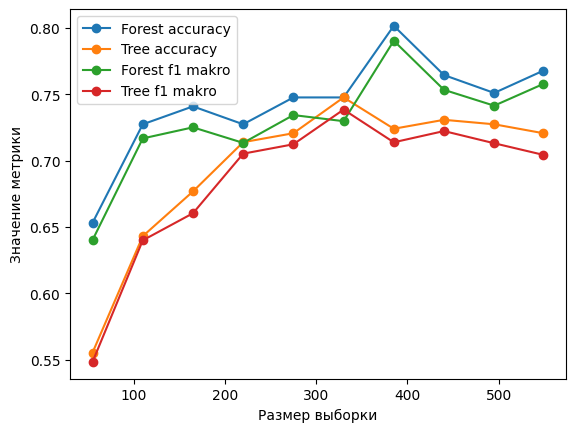

In [108]:

tree_curve = DecisionTreeClassifier(
    random_state=42,
    max_depth=search_tree.best_params_["max_depth"]
    )

accuracy_tree_lc = []
f1_tree_lc = []

for sz in size:

    X_small = X_train[:sz]
    y_small = y_train[:sz]
    tree_curve.fit(X_small, y_small)

    y_pred_tree_cur = tree_curve.predict(X_test)
    accuracy_tree_lc.append(accuracy_score(y_test, y_pred_tree_cur))
    f1_tree_lc.append(f1_score(y_test, y_pred_tree_cur, average="macro"))


plt.plot(size, accuracy_forest_lc, marker="o",
    label="Forest accuracy")
plt.plot(size, accuracy_tree_lc, marker="o",
    label="Tree accuracy")
plt.xlabel("Размер выборки")
plt.ylabel("Значение метрики")
plt.plot(size, f1_forest_lc, marker="o",
    label="Forest f1 makro")
plt.plot(size, f1_tree_lc, marker="o",
    label="Tree f1 makro")
plt.legend()
plt.show()






на текущем графике видно что лес выше одиночного дерева. У дерева заметнее колебания. Это согласуется с тем, что структура одиночного дерева чувствительна к составу обучающей выборки.

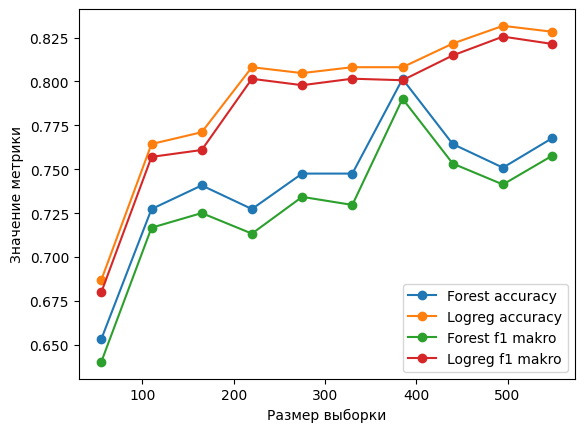

In [109]:

log_curve = LogisticRegression(
     random_state=42,
     C=search.best_params_["C"], 
     solver="saga",
     tol=1e-3, 
     max_iter=2000
    )


accuracy_log_lc = []
f1_log_lc = []

for sz in size:

    X_small = X_train[:sz]
    y_small = y_train[:sz]
    log_curve.fit(X_small, y_small)

    y_pred_log_cur = log_curve.predict(X_test)
    accuracy_log_lc.append(accuracy_score(y_test, y_pred_log_cur))
    f1_log_lc.append(f1_score(y_test, y_pred_log_cur, average="macro"))


plt.plot(size, accuracy_forest_lc, marker="o",
    label="Forest accuracy")
plt.plot(size, accuracy_log_lc, marker="o",
    label="Logreg accuracy")
plt.xlabel("Размер выборки")
plt.ylabel("Значение метрики")
plt.plot(size, f1_forest_lc, marker="o",
    label="Forest f1 makro")
plt.plot(size, f1_log_lc, marker="o",
    label="Logreg f1 makro")
plt.legend()
plt.show()






На графике логистическая регрессия опережает лес при всех десяти размерах выборки по обеим метрикам. У леса accuracy на первой и полной выборках равна 0.653 и 0.768, у регрессии — 0.687 и 0.828.

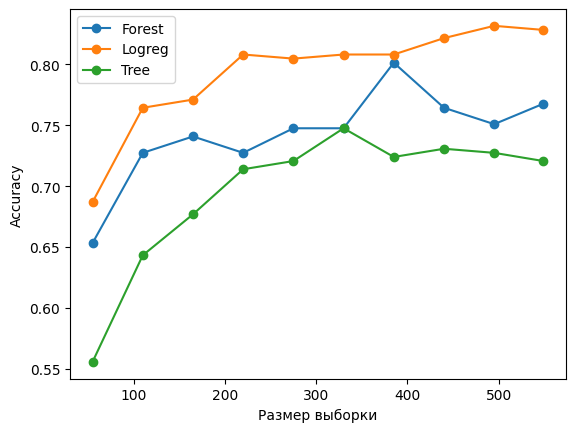

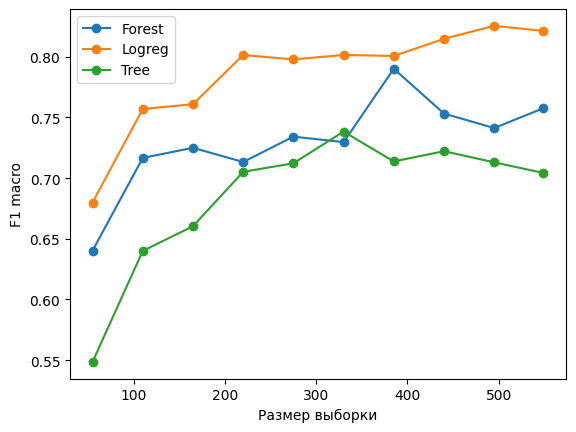

In [110]:

plt.plot(size, accuracy_forest_lc, marker="o",
    label="Forest")
plt.plot(size, accuracy_log_lc, marker="o",
    label="Logreg")
plt.plot(size, accuracy_tree_lc, marker="o",
    label="Tree")
plt.xlabel("Размер выборки")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


plt.plot(size, f1_forest_lc, marker="o",
    label="Forest")
plt.plot(size, f1_log_lc, marker="o",
    label="Logreg")
plt.plot(size, f1_tree_lc, marker="o",
    label="Tree")
plt.xlabel("Размер выборки")
plt.ylabel("F1 macro")
plt.legend()
plt.show()

На полной обучающей выборке получились такие результаты.

- Одно дерево: accuracy около 0.721, F1 около 0.704.
- Лес: accuracy около 0.768, F1 около 0.758.
- Логистическая регрессия: accuracy около 0.828, F1 около 0.821.

С ростом выборки качество растёт у всех трёх моделей. Сильнее всего прибавляет одно дерево: accuracy выросла примерно на 0.165, с 0.556 до 0.721. Логистическая регрессия лучше всех при любом размере выборки, лес находится между ней и деревом. К концу кривые выходят на плато

In [111]:
accuracy_tree_lc[-1] - accuracy_tree_lc[0]

0.164983164983165

#### 2.9. Boosting
Your goal is to build a boosting ensemble using xgboost, CatBoost or lightgbm package.
Please, do not use the sklearn API for these models.

Find optimal number of decision trees in the boosting ensembe using grid search or other methods.
Please, explain your answer.

In [112]:
# YOUR CODE HERE
print(y_train[:10])
print(np.unique(y_train))

['van' 'opel' 'bus' 'bus' 'bus' 'bus' 'opel' 'saab' 'saab' 'saab']
['bus' 'opel' 'saab' 'van']


In [113]:
classes, y_train_num = np.unique(y_train, return_inverse=True)
y_train_num[:10]
print(classes)

['bus' 'opel' 'saab' 'van']


In [114]:
import xgboost as xgb

dtrain = xgb.DMatrix(X_train, label=y_train_num)
print(dtrain.num_row(), dtrain.num_col())

params = {
    "objective": "multi:softprob",
    "num_class": len(classes),
    "eval_metric": "merror",
    "seed": 42
}
print(params)

549 18
{'objective': 'multi:softprob', 'num_class': 4, 'eval_metric': 'merror', 'seed': 42}


In [115]:
cv_results = xgb.cv(
    params=params,
    dtrain=dtrain,
    num_boost_round=500,
    nfold=5,
    stratified=True,
    seed=42
)

print(cv_results.shape)
print(cv_results.head())

(500, 4)
   train-merror-mean  train-merror-std  test-merror-mean  test-merror-std
0           0.110216          0.024985          0.324237         0.036715
1           0.079244          0.015036          0.296947         0.025332
2           0.056468          0.005851          0.300667         0.042103
3           0.039620          0.003434          0.291543         0.033099
4           0.026411          0.003086          0.287790         0.009021


In [116]:
errors = cv_results["test-merror-mean"]
best_index = errors.idxmin()
print(best_index)
print(errors.min())

193
0.24231859883236026


In [118]:
best_rounds = best_index + 1

booster = xgb.train(
    params=params,
    dtrain=dtrain,
    num_boost_round=best_rounds
)

dtest = xgb.DMatrix(X_test)
y_prob_boost = booster.predict(dtest)

class_idx = np.argmax(y_prob_boost, axis=1)
y_pred_boost = classes[class_idx]
count = y_test == y_pred_boost

accuracy_xgb = accuracy_score(y_test, y_pred_boost)
f1_xgb = f1_score(y_test, y_pred_boost, average="macro")
print(accuracy_xgb, f1_xgb)
print(sum(count))

0.7777777777777778 0.7724717652808227
231


Выбрано 194 раундa, так как средняя ошибка на кросс-валидации была минимальной — около 24.2%. На тесте правильно определены 231 из 297 машин. Accuracy около 0.777, F1 около 0.772.

